In [20]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import scipy
import math
import sourmash
import collections

import seaborn as sns


In [21]:
covcurve_df = pl.read_csv('../outputs.isect/isect_kmers_coverage_fits.csv')

In [22]:
gcp_df = pl.read_csv('../outputs.isect/*.isect.abund.csv')
gcp_df

metag,species,abund,method
str,str,f64,str
"""ERR3212028""","""s__Bariatricus sp004560705""",1.830113,"""gcp"""
"""ERR3211889""","""s__Bariatricus sp004560705""",1.778884,"""gcp"""
"""SRR8960468""","""s__Bariatricus sp004560705""",1.717835,"""gcp"""
"""SRR8960622""","""s__Bariatricus sp004560705""",11.019683,"""gmm"""
"""SRR11126389""","""s__Bariatricus sp004560705""",1.46813,"""gcp"""
…,…,…,…
"""SRR11125751""","""s__UBA2868 sp004552595""",5.824612,"""gcp"""
"""SRR11183692""","""s__UBA2868 sp004552595""",15.691013,"""gmm"""
"""ERR3211805""","""s__UBA2868 sp004552595""",13.477577,"""gmm"""


In [23]:
all_df = covcurve_df.join(gcp_df, on=['metag', 'species'])
all_df

species,metag,intersect_bp,weighted_bp,fit_breadth,fit_depth,curve_breadth,abund,method
str,str,i64,i64,f64,f64,f64,f64,str
"""s__Bariatricus sp004560705""","""ERR3212028""",384000,708000,0.342105,0.630756,0.328791,1.830113,"""gcp"""
"""s__Bariatricus sp004560705""","""ERR3211889""",474000,821000,0.422286,0.731428,0.37017,1.778884,"""gcp"""
"""s__Bariatricus sp004560705""","""SRR8960468""",448000,880000,0.399123,0.783991,0.390751,1.717835,"""gcp"""
"""s__Bariatricus sp004560705""","""SRR8960622""",1014000,5675000,0.903371,5.055851,0.959058,11.019683,"""gmm"""
"""s__Bariatricus sp004560705""","""SRR11126389""",295000,428000,0.262815,0.381305,0.214164,1.46813,"""gcp"""
…,…,…,…,…,…,…,…,…
"""s__UBA2868 sp004552595""","""SRR11125751""",144000,669000,0.0718,0.333573,0.1081,5.824612,"""gcp"""
"""s__UBA2868 sp004552595""","""SRR11183692""",1484000,20458000,0.739944,10.200655,0.969754,15.691013,"""gmm"""
"""s__UBA2868 sp004552595""","""ERR3211805""",423000,2616000,0.210914,1.304375,0.360676,13.477577,"""gmm"""


Text(0, 0.5, 'gcp depth estimates')

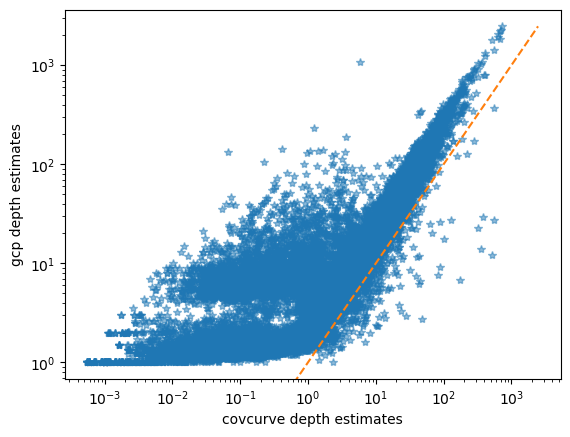

In [24]:
plt.loglog(all_df['fit_depth'], all_df['abund'], '*', alpha=0.5)
maxmax = max(all_df['fit_depth'].max(), all_df['abund'].max())
plt.loglog([0, maxmax], [0, maxmax], '--')
plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')

## Just gmm?

(0.0, 800.0)

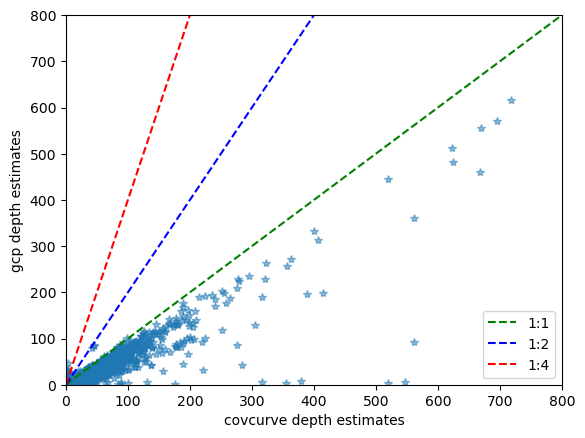

In [38]:
xx_df = all_df.filter(pl.col('method') == 'gmm')

plt.plot(xx_df['fit_depth'], 1/4 * xx_df['abund'], '*', alpha=0.5)
maxmax = max(xx_df['fit_depth'].max(), xx_df['abund'].max())
plt.plot([0, maxmax], [0, maxmax], 'g--', label='1:1')
plt.plot([0, maxmax], [0, 2*maxmax], 'b--', label='1:2')
plt.plot([0, maxmax], [0, 4*maxmax], 'r--', label='1:4')
plt.legend(loc='lower right')

plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')
plt.xlim(0, 800)
plt.ylim(0, 800)
#plt.xlim(0, 5)
#plt.ylim(0, 10)

## Just gcp?

(0.0, 10.0)

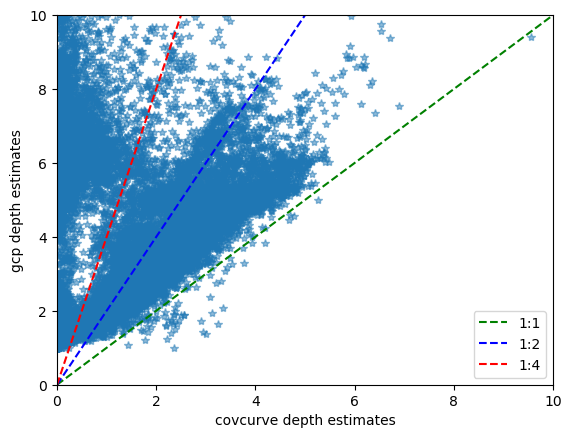

In [41]:
xx_df = all_df.filter(pl.col('method') == 'gcp')

plt.plot(xx_df['fit_depth'], xx_df['abund'], '*', alpha=0.5)
maxmax = max(xx_df['fit_depth'].max(), xx_df['abund'].max())
plt.plot([0, maxmax], [0, maxmax], 'g--', label='1:1')
plt.plot([0, maxmax], [0, 2*maxmax], 'b--', label='1:2')
plt.plot([0, maxmax], [0, 4*maxmax], 'r--', label='1:4')
plt.legend(loc='lower right')

plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')
plt.xlim(0, 10)
plt.ylim(0, 10)
#plt.xlim(0, 5)
#plt.ylim(0, 10)

In [ ]:
plt.plot(all_df['fit_depth'], 1/4 * all_df['abund'], '*', alpha=0.5)
maxmax = max(all_df['fit_depth'].max(), all_df['abund'].max())
plt.plot([0, maxmax], [0, maxmax], 'g--', label='1:1')
plt.plot([0, maxmax], [0, 2*maxmax], 'b--', label='1:2')
plt.plot([0, maxmax], [0, 4*maxmax], 'r--', label='1:4')
plt.legend(loc='lower right')

plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')
plt.xlim(0, 1000)
plt.ylim(0, 1000)
#plt.xlim(0, 5)
#plt.ylim(0, 10)

(0.0, 15.0)

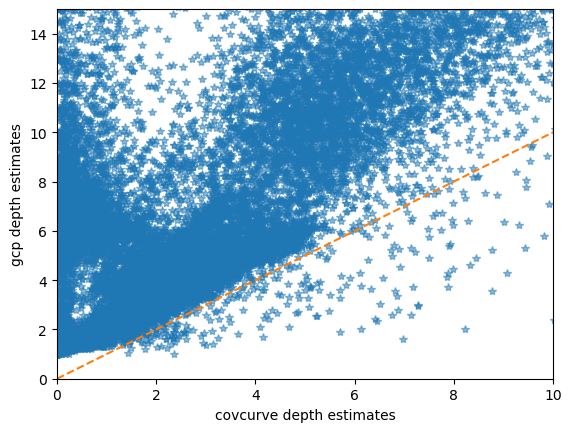

In [27]:
plt.plot(all_df['fit_depth'], all_df['abund'], '*', alpha=0.5)
maxmax = max(all_df['fit_depth'].max(), all_df['abund'].max())
plt.plot([0, maxmax], [0, maxmax], '--')
plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')
plt.xlim(0, 10)
plt.ylim(0, 15)

(0.0, 50.0)

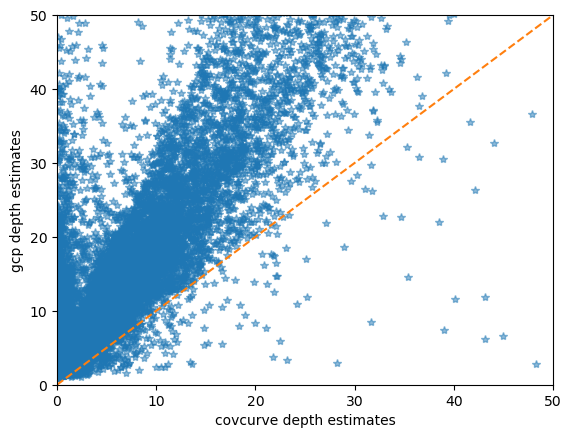

In [28]:
plt.plot(all_df['fit_depth'], all_df['abund'], '*', alpha=0.5)
maxmax = max(all_df['fit_depth'].max(), all_df['abund'].max())
plt.plot([0, maxmax], [0, maxmax], '--')
plt.xlabel('covcurve depth estimates')
plt.ylabel('gcp depth estimates')
plt.xlim(0, 50)
plt.ylim(0, 50)

In [ ]:
all_df.iter

## Examine some plots

In [55]:
def load_plot_isect(species, metag, xx_all_df, *, ymax=50, bins=50):
    ss = list(sourmash.load_file_as_signatures(f'../outputs.isect/3216_isect.d/{species} singlehash.x.{metag}.sig.zip'))[0]

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

     # track hashval abundance distribution
    counts_d = collections.defaultdict(int)
    # track abundance distribution, too
    counter = collections.Counter()

    for hashval, abund in ss.minhash.hashes.items():
        counts_d[hashval] += abund
        counter[abund] += 1

    all_counts = list(counts_d.values())
    counts_dist = list(counter.items())
    sum_hist = sum(counter.values())
    max_range = max(counter.values())
    min_range = 0

    # find count that covers 95% of distribution.
    sofar = 0
    for k, v in sorted(counts_dist):
        sofar += v
        if sofar >= 0.99*sum_hist:
            max_range = 2*k
            break

    fig, ax1 = plt.subplots(nrows=1, ncols=1, figsize=(10, 4))
    sns.histplot(all_counts, ax=ax1,
                 binrange=(min_range, max_range),
                 bins=bins, kde=False, stat='density')

    # retrieve coverage estimates from all_df
    row = xx_all_df.filter((pl.col('metag') == metag) & (pl.col('species') == species.split(' ', 1)[1]))
    row = next(iter(row.iter_rows(named=True)))
    covcurve_depth = row['fit_depth']
    gcp_depth = row['abund']

    ax1.axvline(gcp_depth, color='b', linestyle='--', label='est: gcp')
    ax1.axvline(covcurve_depth, color='g', linestyle='--', label='est: coverage curve')
    ax1.legend(loc='upper right')

    fig.suptitle(f'{species}.x.{metag}')

    plt.show()

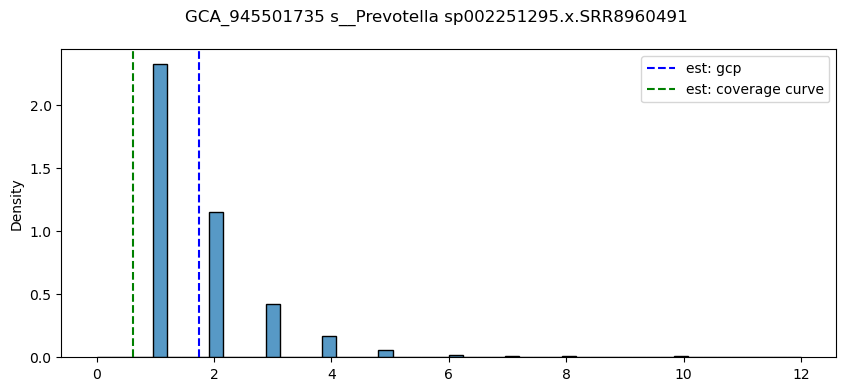

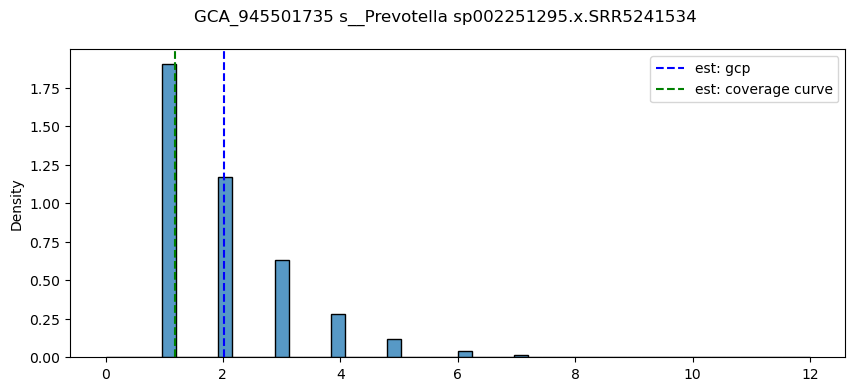

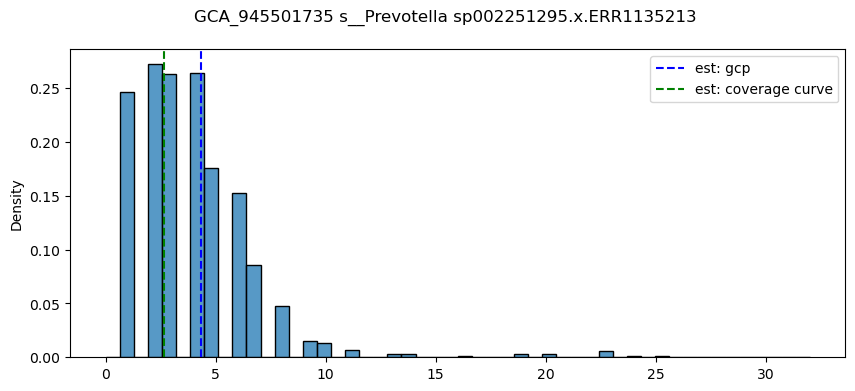

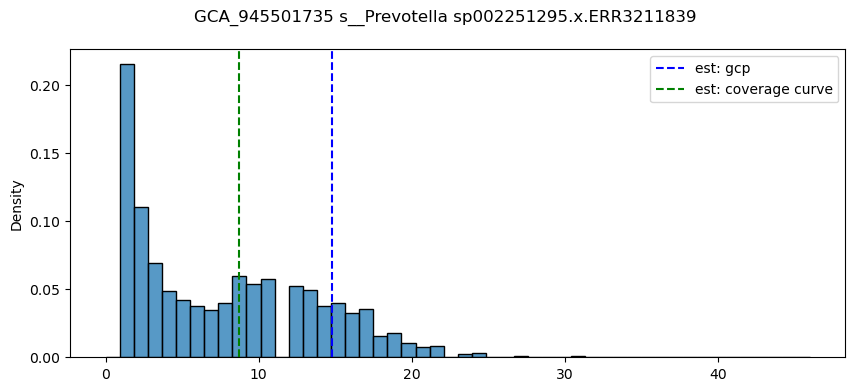

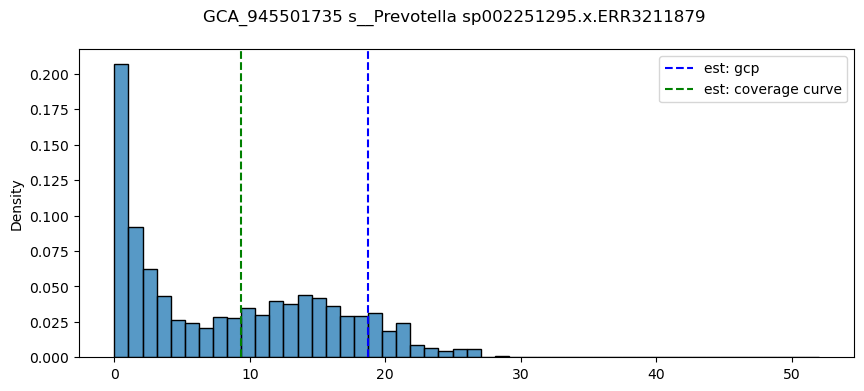

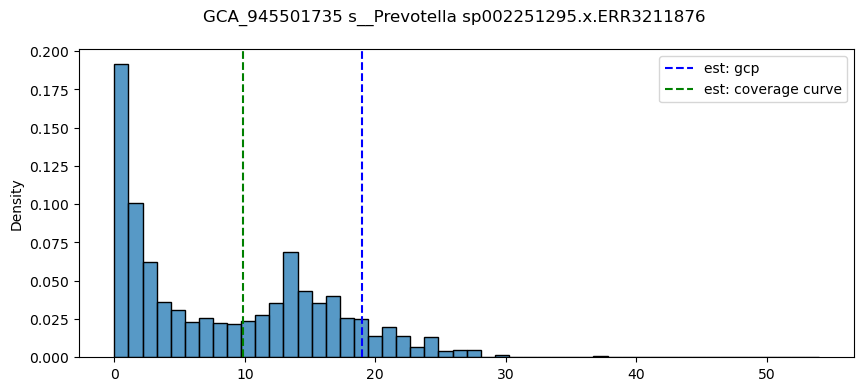

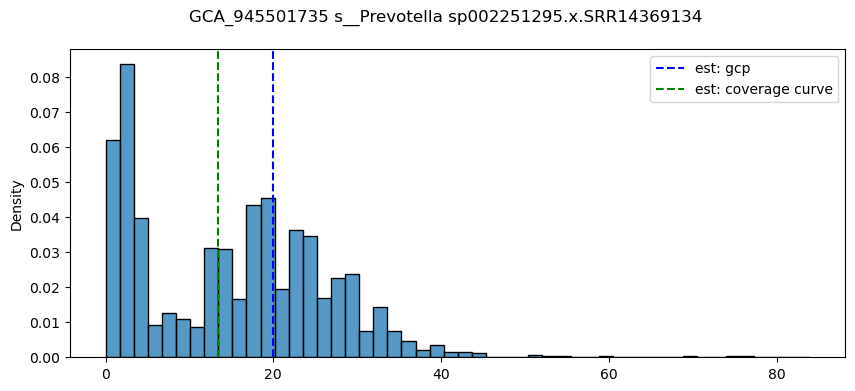

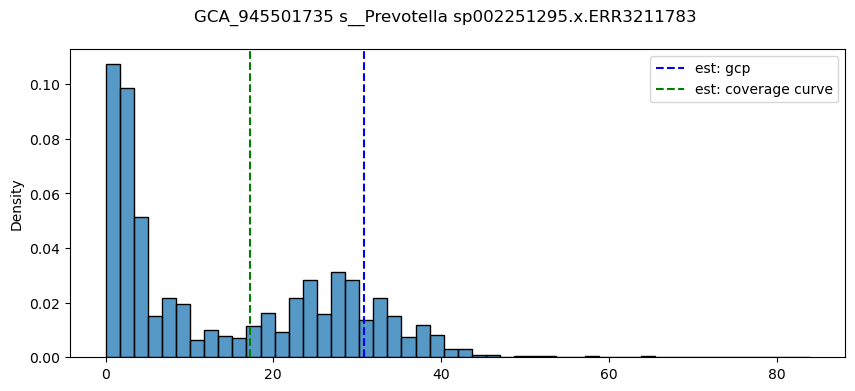

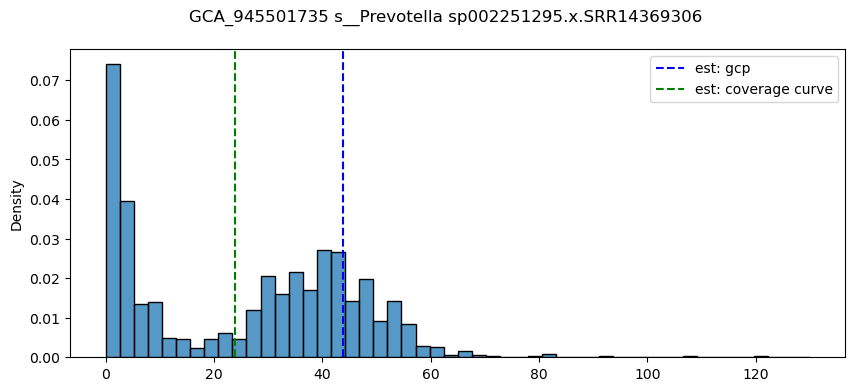

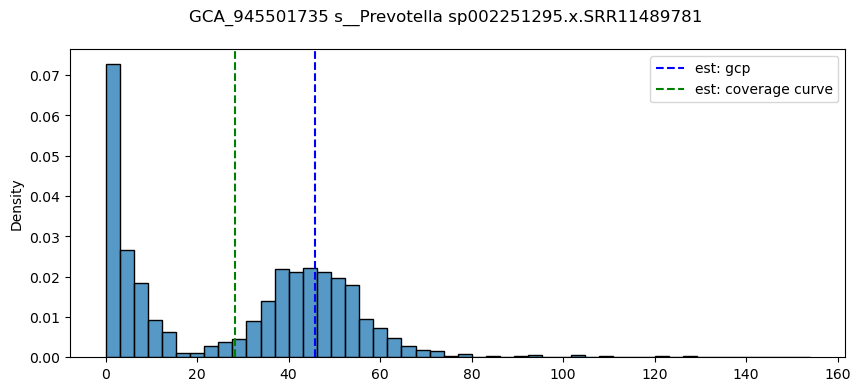

In [56]:
SS='GCA_945501735 s__Prevotella sp002251295'

METAGS=[
 'SRR8960491',
 'SRR5241534',
 'ERR1135213',
 'ERR3211839',
 'ERR3211879',
 'ERR3211876',
 'SRR14369134',
 'ERR3211783',
 'SRR14369306',
 'SRR11489781']

#plot_covhist_panel(SS, METAGS, ymax=100)

for i in METAGS:
    load_plot_isect(SS, i, all_df)

In [58]:
lacto_kmer_df = pl.read_csv('../outputs.isect/s__Lactobacillus amylovorus.isect.abund.csv')
lacto_kmer_df = lacto_kmer_df.sort('abund', descending=True).drop_nans()
lacto_kmer_df

metag,species,abund,method
str,str,f64,str
"""SRR17241521""","""s__Lactobacillus amylovorus""",2467.830265,"""gmm"""
"""SRR11185260""","""s__Lactobacillus amylovorus""",2282.732405,"""gmm"""
"""SRR11185246""","""s__Lactobacillus amylovorus""",2224.495096,"""gmm"""
"""SRR16235702""","""s__Lactobacillus amylovorus""",2045.930849,"""gmm"""
"""SRR16235689""","""s__Lactobacillus amylovorus""",1924.562517,"""gmm"""
…,…,…,…
"""ERR3211990""","""s__Lactobacillus amylovorus""",1.0,"""gcp"""
"""SRR7182060""","""s__Lactobacillus amylovorus""",1.0,"""gcp"""
"""ERR3211821""","""s__Lactobacillus amylovorus""",1.0,"""gcp"""


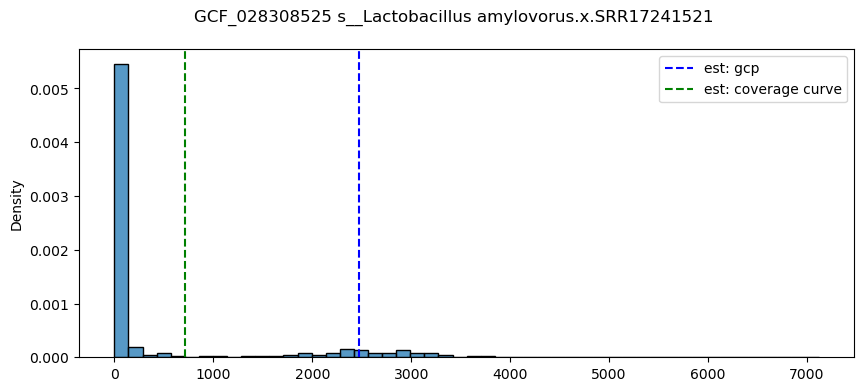

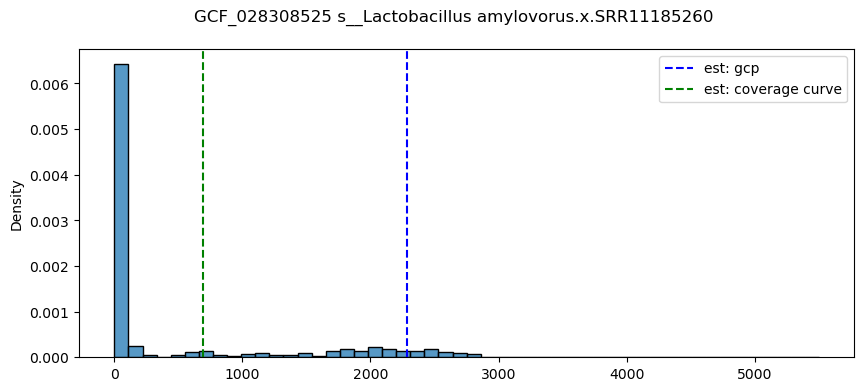

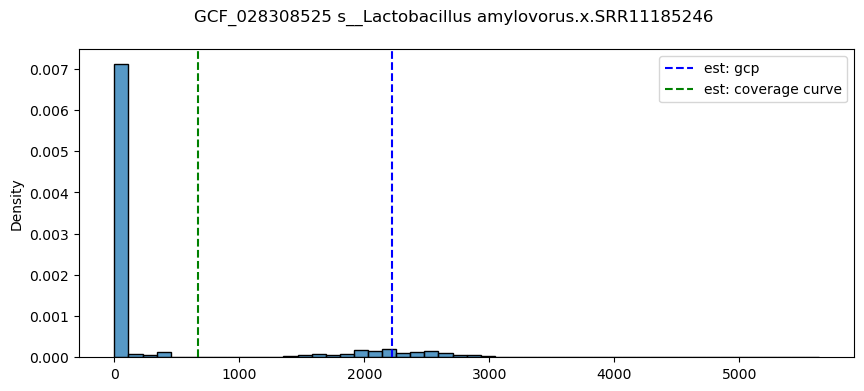

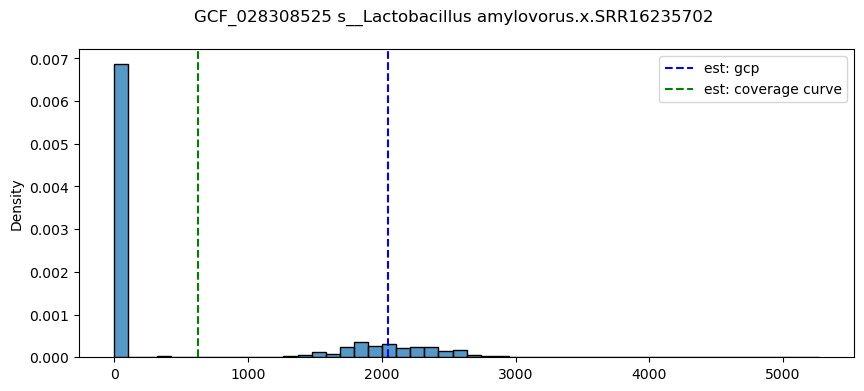

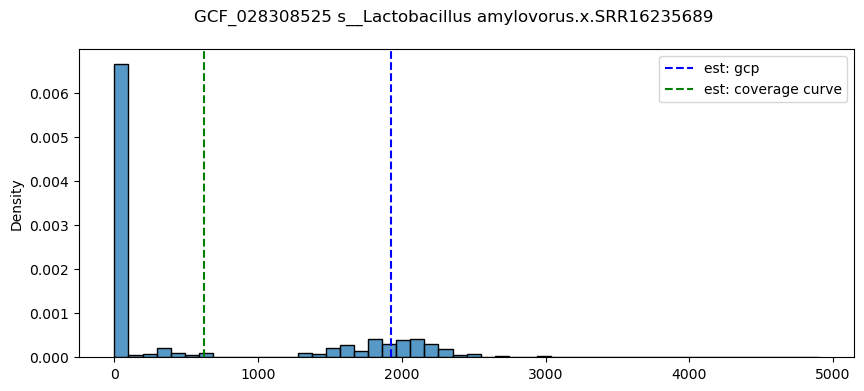

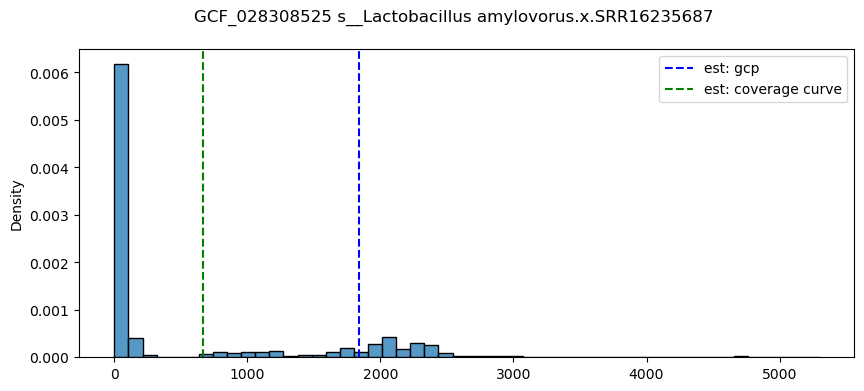

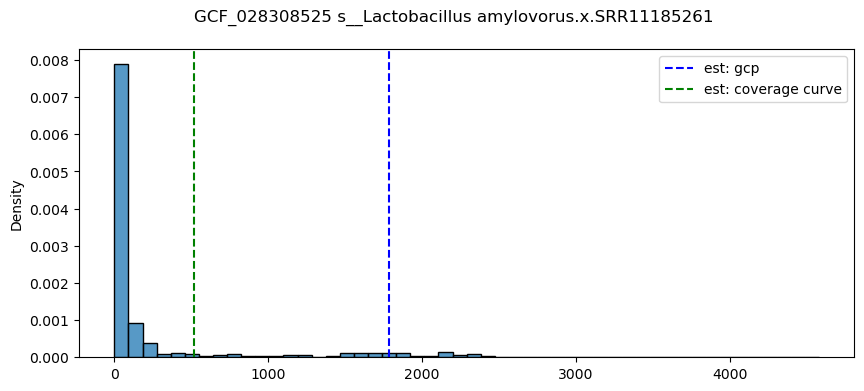

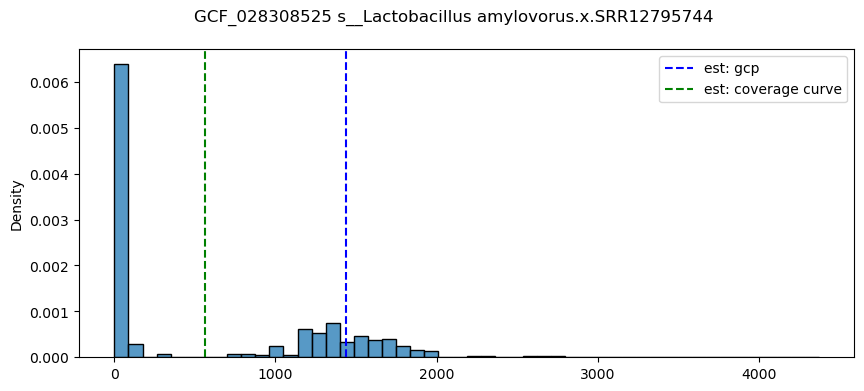

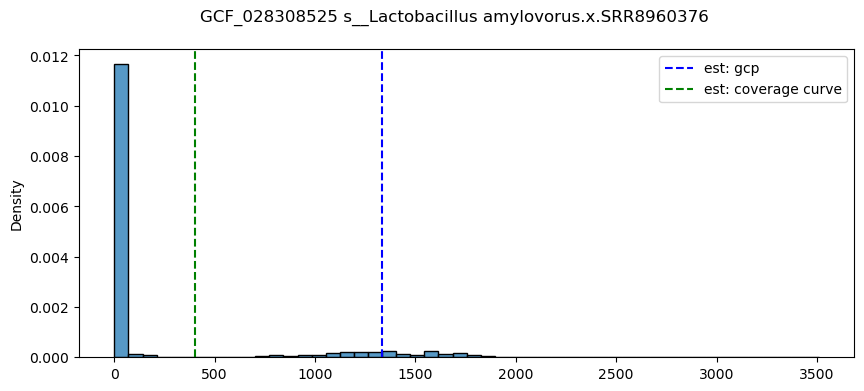

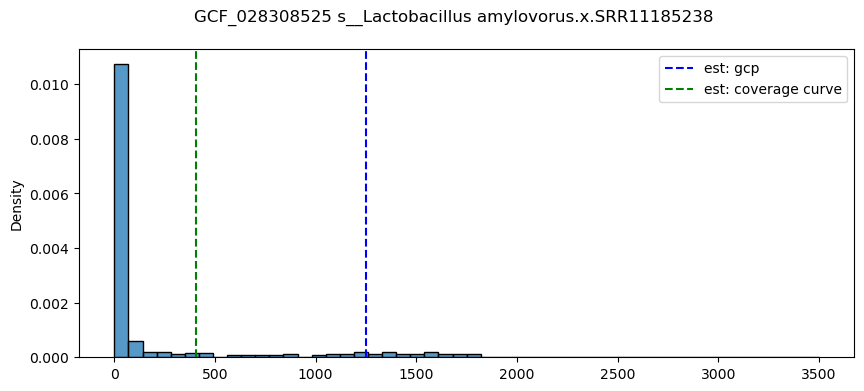

In [60]:
for metag in lacto_kmer_df.head(10)['metag']:
    load_plot_isect('GCF_028308525 s__Lactobacillus amylovorus', metag, all_df)